# LASSI - Power Efficiency

***OLLAMA API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1
    
# We need to reload the prompt dictionary because it is under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.pipeline
%aimport lassi.get_power

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM LMSTUDIO
    # model = "lmstudio-community/Meta-Llama-3-8B-Instruct-GGUF/"
    # model = "TheBloke/CodeLlama-13B-Instruct-GGUF"
    # model = "lmstudio-community/starcoder2-15b-instruct-v0.1-GGUF" - couldn;t generate anything
    # model = "lmstudio-community/stable-code-instruct-3b-GGUF" - couldn't compile, but 'worked'
    # model = "microsoft/Phi-3-mini-4k-instruct-gguf" - generated garbage, and slow
    # model = "lmstudio-community/codegemma-1.1-7b-it-GGUF" - generated code, faster, but not compiled -- more tries
    # model = "lmstudio-community/Codestral-22B-v0.1-GGUF"  # - nice large context size 32768 -- load it on aiop01 at 28 gpu layers

    # -- FROM OLLAMA
    model = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model = "deepseek-coder-v2"  # (max token = 16384)
    # model = "codestral"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 32700

    # ASSIGN LLM API SOURCE:
    if "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "01test_betterpower_withcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"deepseek-r1:70b","created_at":"2025-01-30T18:40:51.596282518Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   167  100   122  100    45   1466    541 --:--:-- --:--:-- --:--:--  2012


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: ollama
Model: deepseek-r1:70b
Model coder: qwen2.5-coder:32b
System Prompt Index: CUDA
Code file template: generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

LLM System Prompt: 

You are a professional coding AI assistant that specializes in refactoring parallelized code to improve energy efficiency by reducing G

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 10.270735 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


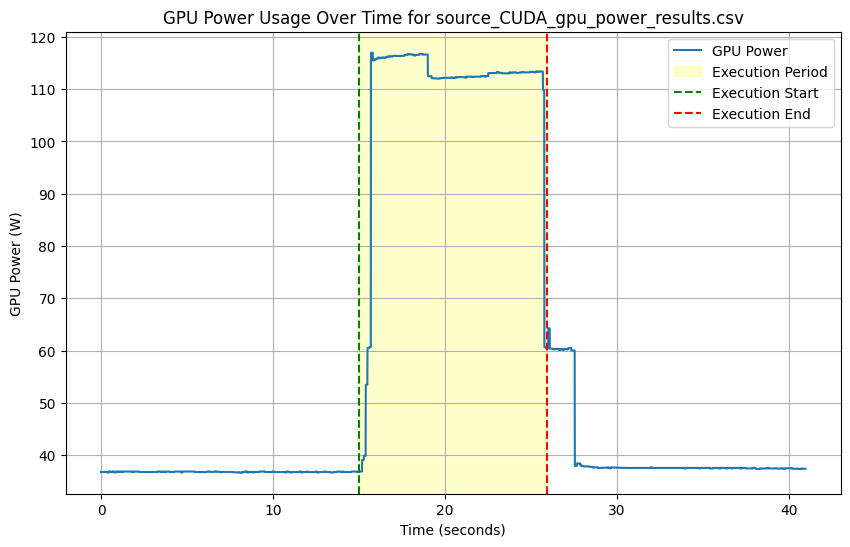

Start time: 15.015 -- End time: 25.941

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.93 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000331 kWh
  0.3306 Wh
  1190.10 J
Average GPU power: 108.88 W
Total Energy During Exe Runtime:   1190.10 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
... Duration for idle time measurement: 10.925763845443726
GPU power data has been written to idle__gpu_power_results.csv


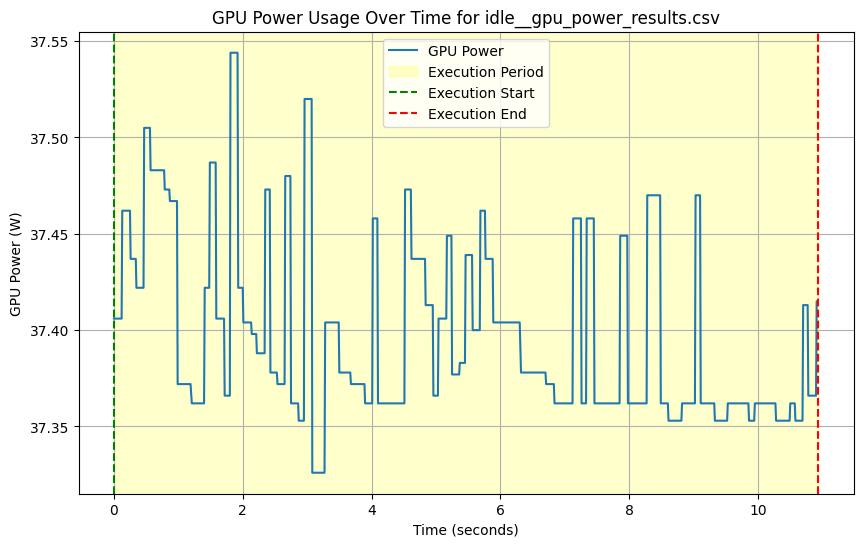

Start time: 0 -- End time: 10.937

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.94 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000114 kWh
  0.1136 Wh
  409.14 J
Average GPU power: 37.40 W
Total Energy During Exe Runtime:   409.14 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----



--> ... prompt LLM to summarize context knowledge.




----- CONTEXT KNOWLEDGE SUMMARY -----
(generated by the LLM)



To optimize your CUDA code effectively, follow this structured approach based on priority and impact:

### High-Priority Optimizations

1. **Minimize Global Memory Access:**
   - **Shared Memory:** Introduce shared memory for data reused within threads. Allocate shared arrays and ensure access patterns avoid bank conflicts through padding or staggered accesses.
   - **Cache Frequently Accessed Data:** Use loop tiling to cache data in shared memory, reducing global memory transactions.

2. **Avoid Divergent Warps:**
   - Restructure code to prevent thread divergence within warps. Use predicates instead of branches where possible. Consider using `__syncwarp()` post-Volta to ensure warp convergence after divergent sections.

### Medium-Priority Optimizations

3. **Loop Unrolling:**
   - Experiment with loop unrolling factors (e.g., 4) to increase data processed per iteration, reducing overhead. Use `#pragma unroll` where beneficial.

4. **Math Function Optimization:**
   - Replace `sqrt(x)` with `sqrtf(x)` for faster computation.
   - Use `x*x` instead of `pow(x, 2)` and consider fast exponentiation functions like `expf()` if precision allows.

5. **Trigonometric Function Replacement:**
   - Replace `sin(π*expr)` with `sinpi(expr)` and similarly for cosine functions to improve both accuracy and performance.

### Low-Priority but Impactful Optimizations

6. **Memory Coalescing:**
   - Restructure data layout to ensure coalesced memory accesses, possibly changing from row-major to column-major order if beneficial.

7. **Register Blocking:**
   - Process small data blocks in registers to minimize memory transactions, balancing code complexity and performance gains.

### Additional Recommendations

8. **Profiling:**
   - Use CUDA profiling tools post-optimization to identify remaining bottlenecks and guide further optimizations.

By addressing high-priority items first, such as reducing global memory access and avoiding divergent warps, you can achieve significant performance improvements. Subsequent steps on loop unrolling and math functions will further enhance efficiency. Profiling after each major change will help refine your approach effectively.


--> ... prompt LLM to describe the source code.




----- CODE DESCRIPTION -----
(generated by the LLM)



The provided C code is a CUDA implementation of a fluid dynamics simulation, solving the Navier-Stokes equations using iterative methods on a GPU. Here's a breakdown of its key components:

1. **Memory Allocation**: The code allocates memory on both the host (CPU) and device (GPU) for various fields including velocities (`u`, `v`), intermediate fields (`F`, `G`), pressure fields (`pres_red`, `pres_black`), residuals, and maximum velocity arrays.

2. **Simulation Loop**: A while loop runs until the simulation time exceeds 10 units. Within each iteration:
   - The time step (`dt`) is calculated based on the maximum velocities to ensure numerical stability.
   - CUDA kernels compute intermediate fields (`calculate_F`, `calculate_G`).
   - Mass conservation is enforced using a sum and scaling of pressure fields.
   - A Successive Over-Relaxation (SOR) method iteratively solves the pressure Poisson equation until convergence, indicated by a residual below a tolerance.

3. **Velocity Update**: After solving for pressure, new velocities are computed using CUDA kernels (`calculate_u`, `calculate_v`), ensuring incompressibility.

4. **Boundary Conditions**: A kernel (`set_BCs`) applies boundary conditions to the velocity fields on the GPU.

5. **Timing and Profiling**: The simulation measures execution time using CUDA events to benchmark performance.

6. **Data Output**: Final velocity fields are written to a file, with values averaged for smoother visualization.

7. **Memory Management**: All allocated memory is freed post-simulation to prevent leaks.

This code efficiently leverages GPU parallelism for scientific computing, employing iterative solvers and dynamic time stepping typical in fluid dynamics simulations.

... (8 outputs left out)

```cpp
#include <iostream>

__global__ void calculate_u_kernel(float* u, const float* F, const float* G, int nx, int ny, float dx, float dy, float dt) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int j = blockIdx.y * blockDim.y + threadIdx.y;

    if (i < nx && j < ny) {
        u[j * nx + i] = u[j * nx + i] + dt * ((F[j * nx + i] / dx) - (F[(j + 1) * nx + i] / dx) +
                                              (G[j * nx + i] / dy) - (G[j * nx + (i + 1)] / dy));
    }
}

__global__ void calculate_v_kernel(float* v, const float* F, const float* G, int nx, int ny, float dx, float dy, float dt) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int j = blockIdx.y * blockDim.y + threadIdx.y;

    if (i < nx && j < ny) {
        v[j * nx + i] = v[j * nx + i] + dt * ((F[(j + 1) * nx + i] / dx) - (F[j * nx + i] / dx) +
                                              (G[j * nx + (i + 1)] / dy) - (G[j * nx + i] / dy));
    }
}

__global__ void calculate_max_u_kernel(const float* u, float* max_u, int nx, int ny) {
    extern __shared__ float sdata[];

    unsigned int tid = threadIdx.x;
    unsigned int i = blockIdx.x * blockDim.x + threadIdx.x;
    unsigned int j = blockIdx.y * blockDim.y + threadIdx.y;

    if (i < nx && j < ny) {
        sdata[tid] = u[j * nx + i];
    } else {
        sdata[tid] = 0.0f;
    }
    __syncthreads();

    for (unsigned int s = blockDim.x / 2; s > 0; s >>= 1) {
        if (tid < s) {
            sdata[tid] = fmax(sdata[tid], sdata[tid + s]);
        }
        __syncthreads();
    }

    if (tid == 0) {
        atomicMax((unsigned int*)max_u, __float_as_uint(sdata[0]));
    }
}

__global__ void calculate_max_v_kernel(const float* v, float* max_v, int nx, int ny) {
    extern __shared__ float sdata[];

    unsigned int tid = threadIdx.x;
    unsigned int i = blockIdx.x * blockDim.x + threadIdx.x;
    unsigned int j = blockIdx.y * blockDim.y + threadIdx.y;

    if (i < nx && j < ny) {
        sdata[tid] = v[j * nx + i];
    } else {
        sdata[tid] = 0.0f;
    }
    __syncthreads();

    for (unsigned int s = blockDim.x / 2; s > 0; s >>= 1) {
        if (tid < s) {
            sdata[tid] = fmax(sdata[tid], sdata[tid + s]);
        }
        __syncthreads();
    }

    if (tid == 0) {
        atomicMax((unsigned int*)max_v, __float_as_uint(sdata[0]));
    }
}

int main() {
    const int nx = 256;
    const int ny = 256;
    const float dx = 1.0f / (nx - 1);
    const float dy = 1.0f / (ny - 1);
    const float dt = 0.01f;

    // Allocate memory on host
    float* h_u = new float[nx * ny];
    float* h_v = new float[nx * ny];
    float* h_F = new float[nx * ny];
    float* h_G = new float[nx * ny];

    // Initialize data on host
    for (int j = 0; j < ny; ++j) {
        for (int i = 0; i < nx; ++i) {
            h_u[j * nx + i] = 0.0f;
            h_v[j * nx + i] = 0.0f;
            h_F[j * nx + i] = 1.0f; // Example boundary condition
            h_G[j * nx + i] = 0.0f;
        }
    }

    // Allocate memory on device
    float* d_u, *d_v, *d_F, *d_G, *d_max_u, *d_max_v;
    cudaMalloc(&d_u, nx * ny * sizeof(float));
    cudaMalloc(&d_v, nx * ny * sizeof(float));
    cudaMalloc(&d_F, nx * ny * sizeof(float));
    cudaMalloc(&d_G, nx * ny * sizeof(float));
    cudaMalloc(&d_max_u, sizeof(float));
    cudaMalloc(&d_max_v, sizeof(float));

    // Copy data from host to device
    cudaMemcpy(d_u, h_u, nx * ny * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_v, h_v, nx * ny * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_F, h_F, nx * ny * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_G, h_G, nx * ny * sizeof(float), cudaMemcpyHostToDevice);

    // Set up execution configuration
    dim3 blockSize(16, 16);
    dim3 gridSize((nx + blockSize.x - 1) / blockSize.x, (ny + blockSize.y - 1) / blockSize.y);

    // Initialize max_u and max_v on device
    float init_max = 0.0f;
    cudaMemcpy(d_max_u, &init_max, sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_max_v, &init_max, sizeof(float), cudaMemcpyHostToDevice);

    // Perform computation
    for (int iter = 0; iter < 100; ++iter) {
        calculate_u_kernel<<<gridSize, blockSize>>>(d_u, d_F, d_G, nx, ny, dx, dy, dt);
        calculate_v_kernel<<<gridSize, blockSize>>>(d_v, d_F, d_G, nx, ny, dx, dy, dt);

        // Reset max_u and max_v
        cudaMemcpy(d_max_u, &init_max, sizeof(float), cudaMemcpyHostToDevice);
        cudaMemcpy(d_max_v, &init_max, sizeof(float), cudaMemcpyHostToDevice);

        calculate_max_u_kernel<<<gridSize, blockSize, blockSize.x * sizeof(float)>>>(d_u, d_max_u, nx, ny);
        calculate_max_v_kernel<<<gridSize, blockSize, blockSize.x * sizeof(float)>>>(d_v, d_max_v, nx, ny);

        // Synchronize to ensure all threads have completed
        cudaDeviceSynchronize();

        // Copy max_u and max_v back to host for inspection
        cudaMemcpy(&init_max, d_max_u, sizeof(float), cudaMemcpyDeviceToHost);
        std::cout << "Max u at iteration " << iter << ": " << init_max << std::endl;

        cudaMemcpy(&init_max, d_max_v, sizeof(float), cudaMemcpyDeviceToHost);
        std::cout << "Max v at iteration " << iter << ": " << init_max << std::endl;
    }

    // Copy results back to host
    cudaMemcpy(h_u, d_u, nx * ny * sizeof(float), cudaMemcpyDeviceToHost);
    cudaMemcpy(h_v, d_v, nx * ny * sizeof(float), cudaMemcpyDeviceToHost);

    // Free device memory
    cudaFree(d_u);
    cudaFree(d_v);
    cudaFree(d_F);
    cudaFree(d_G);
    cudaFree(d_max_u);
    cudaFree(d_max_v);

    // Free host memory
    delete[] h_u;
    delete[] h_v;
    delete[] h_F;
    delete[] h_G;

    return 0;
}
```

### Explanation:
1. **Kernel Functions**:
   - `calculate_u_kernel` and `calculate_v_kernel`: These kernels update the velocity fields `u` and `v` based on the given finite difference equations.
   - `calculate_max_u_kernel` and `calculate_max_v_kernel`: These kernels find the maximum value in the `u` and `v` arrays, respectively. They use shared memory to perform a reduction operation.

2. **Main Function**:
   - Memory allocation: Host and device memory are allocated for the velocity fields (`u`, `v`) and forcing terms (`F`, `G`).
   - Initialization: The host arrays are initialized with example values.
   - Data transfer: The host data is copied to the device.
   - Execution configuration: Grid and block sizes are defined for the kernel launches.
   - Iterative computation: The main loop runs a specified number of iterations, updating the velocity fields and finding their maximum values at each step.
   - Synchronization: `cudaDeviceSynchronize` ensures that all threads have completed their tasks before proceeding to the next iteration.
   - Data transfer back to host: After computations, the results are copied back to the host for inspection.

3. **Atomic Operations**:
   - The `atomicMax` function is used in the reduction kernels to ensure thread-safe updates of the maximum values.

This code provides a basic framework for simulating fluid dynamics using finite difference methods on a GPU with CUDA. Adjustments can be made based on specific requirements and boundary conditions.

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

Compilation of code successful!

Execute file: generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

Unloading Ollama server...

Unload LLM:
 {"model":"deepseek-r1:70b","created_at":"2025-01-30T18:54:13.871979625Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   167  100   122  100    45  55303

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext', '']

Max u at iteration 0: 0
Max v at iteration 0: 0
Max u at iteration 1: 0
Max v at iteration 1: 0
Max u at iteration 2: 0
Max v at iteration 2: 0
Max u at iteration 3: 0
Max v at iteration 3: 0
Max u at iteration 4: 0
Max v at iteration 4: 0
Max u at iteration 5: 0
Max v at iteration 5: 0
Max u at iteration 6: 0
Max v at iteration 6: 0
Max u at iteration 7: 0
Max v at iteration 7: 0
Max u at iteration 8: 0
Max v at iteration 8: 0
Max u at iteration 9: 0
Max v at iteration 9: 0
Max u at iteration 10: 0
Max v at iteration 10: 0
Max u at iteration 11: 0
Max v at iteration 11: 0
Max u at iteration 12: 0
Max v at iteration 12: 0
Max u at iteration 13: 0
Max v at iteration 13: 0
Max u at iteration 14: 0
Max v at iteration 14: 0
Max u at iteration 15: 0
Max v at iteration 15: 0
Max u at iteration 16: 0
Max v at iteration 16: 0
Max u at iteration 17: 0
Max v at iteration 17: 0
Max u at 

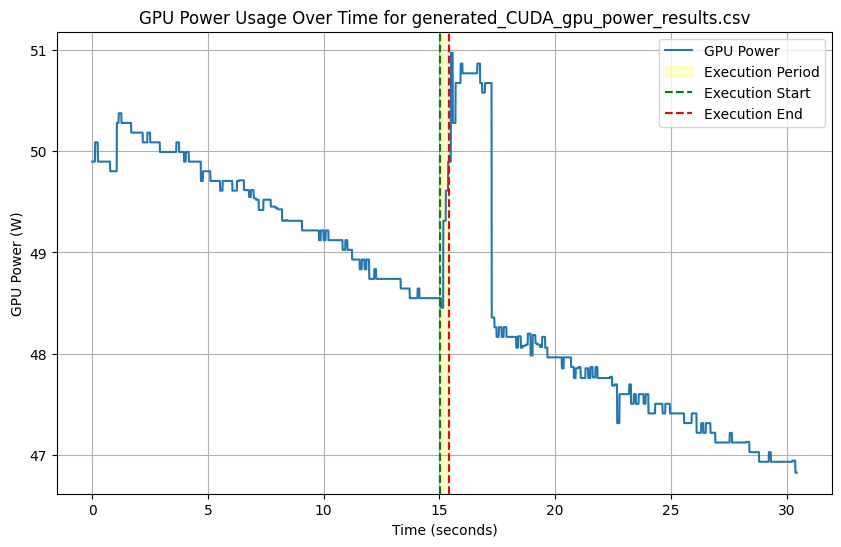

Start time: 15.015 -- End time: 15.413

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 0.40 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000005 kWh
  0.0055 Wh
  19.66 J
Average GPU power: 49.12 W
Total Energy During Exe Runtime:   19.66 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 1190.0985382624704
  total_energy_joules: -389.4779344736842
  sourcecode_ave_power: 108.8827516158818
  ave_power: 11.722846153846142
  runtime_sourcecode: 10.925763845443726


NameError: name 'duraction_refactor' is not defined

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()


# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BEGIN GENERAL CUDA PROGRAMMING CONTEXT] " + prompts.get_codeknowledge("cuda") + " [/END GENERAL CUDA PROGRAMMING CONTEXT]\n\n "
input_context = input_context + " [BEGIN CUDA OPTIMIZATION CONTEXT] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + " [/END CUDA OPTIMIZATION CONTEXT]\n\n "


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [14]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'